In [25]:
data = 'https://raw.githubusercontent.com/alexeygrigorev/mlbookcamp-code/master/chapter-03-churn-prediction/WA_Fn-UseC_-Telco-Customer-Churn.csv'
!curl -o data-week-3.csv $data

  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100  954k  100  954k    0     0   921k      0  0:00:01  0:00:01 --:--:--  922k


In [120]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
# اول حاجة استدعينا المكاتب 
df=pd.read_csv(data)
df.head().T# قرينا الملف ليه بدلنا الصفوف بالاعمدة عشان الاعمدة كتير الشاشة ما حتجبهم كلهم بشكل عمودي لكن لما يكون بشكل افقي حتجبهم 
df.head()# هان حيطبع كم عمود وبعدين يختصر 
df.shape# هان شكل ملف البيانات 

(7043, 21)

In [121]:
df.columns=df.columns.str.lower().str.replace(' ','_')# هان اسما الاعمدة بنخليهم كلهم حروف صغيرة والمسافة بنحط شرطة 
categorical_columns=list(df.dtypes[df.dtypes=='object'].index)# هان بنعمل ليستا فيها الاعمدة النصوص وبنجيب القيم 
for col in categorical_columns:# بنعمل للوب علي لستا الاعمدة النصوص 
    df[col]=df[col].str.lower().str.replace(' ','_')# هان بنجيب عمود عمود ونطبق عليه الحرف صغيرة تبديل المسافات في شرطات 
df.head()# نطبع النتايج 

,customerid,gender,seniorcitizen,partner,dependents,tenure,phoneservice,multiplelines,internetservice,onlinesecurity,...,deviceprotection,techsupport,streamingtv,streamingmovies,contract,paperlessbilling,paymentmethod,monthlycharges,totalcharges,churn
0,7590-vhveg,female,0,yes,no,1,no,no_phone_service,dsl,no,...,no,no,no,no,month-to-month,yes,electronic_check,29.85,29.85,no
1,5575-gnvde,male,0,no,no,34,yes,no,dsl,yes,...,yes,no,no,no,one_year,no,mailed_check,56.95,1889.5,no
2,3668-qpybk,male,0,no,no,2,yes,no,dsl,yes,...,no,no,no,no,month-to-month,yes,mailed_check,53.85,108.15,yes
3,7795-cfocw,male,0,no,no,45,no,no_phone_service,dsl,yes,...,yes,yes,no,no,one_year,no,bank_transfer_(automatic),42.30,1840.75,no
4,9237-hqitu,female,0,no,no,2,yes,no,fiber_optic,no,...,no,no,no,no,month-to-month,yes,electronic_check,70.70,151.65,yes


In [122]:
df.dtypes # هان بنعمل كشف الانواع البيانات الموجودة 
# واثنا الكشف بنلاحظ متغير totalcharges هو مجموع الاشتركات نص كيف كدا المفروض رقم 

customerid           object
gender               object
seniorcitizen         int64
partner              object
dependents           object
tenure                int64
phoneservice         object
multiplelines        object
internetservice      object
onlinesecurity       object
onlinebackup         object
deviceprotection     object
techsupport          object
streamingtv          object
streamingmovies      object
contract             object
paperlessbilling     object
paymentmethod        object
monthlycharges      float64
totalcharges         object
churn                object
dtype: object

In [123]:
#pd.to_numeric(df.totalcharges) 
# بنيجي نحوله الرقم في سهولة لكن يعمل غلط بسبب انو في قيم كان فاضية عبارة عن مسافة ولما عملنا التحويل تبع الاعمدة النصوص حط بدل المسافة شرطة 
tc=pd.to_numeric(df.totalcharges,errors='coerce')# هان رجعنا حولنا العمود الي ارقام وحكينا لو واجهت غلط حول قيم الغلط الي قيم نان 
tc.isnull().sum()#وهان جمعنا كم قيمة نان صار عنا بنلاقي ١١
# مين هدول القيم الغلط الي غلط هما ١١ عميل جداد تم اضافتهم جديد وما عملو الهم فواتير 


np.int64(11)

In [124]:
df[tc.isnull()][['customerid', 'totalcharges']]
# بنيجي نتاكد طلع النا قيم النان من عمود الاعملا المقابل الهم من المجموع
# بنكتشف انو هما ١١ فعلا عملا جداد 

,customerid,totalcharges
488,4472-lvygi,_
753,3115-czmzd,_
936,5709-lvoeq,_
1082,4367-nuyao,_
1340,1371-dwpaz,_
3331,7644-omvmy,_
3826,3213-vvolg,_
4380,2520-sgtta,_
5218,2923-arzlg,_
6670,4075-wkniu,_


In [125]:
df.totalcharges=pd.to_numeric(df.totalcharges,errors='coerce')
# هان عدلنا علي العمود القيم الشرطات الي بعملو غلط اثنا التحويل حطهم نان 
df.totalcharges=df.totalcharges.fillna(0)
# وهان بنعدل علي العمود القيم نان الي طلعتهم عوضهم بصفر 
df.head().T
# نطبع نشوف نتايج
df.totalcharges

0         29.85
1       1889.50
2        108.15
3       1840.75
4        151.65
         ...   
7038    1990.50
7039    7362.90
7040     346.45
7041     306.60
7042    6844.50
Name: totalcharges, Length: 7043, dtype: float64

In [126]:
df.churn#.head()
# هان بدنا نطلع علي نتايج عمود النتايج بنكتشف انو مكتوب بالننص واحنا الحين بدنا نحوله بالارقام صفر العميل ما حيترك الشركة وواحد العميل ترك الشركة 

0        no
1        no
2       yes
3        no
4       yes
       ... 
7038     no
7039     no
7040     no
7041    yes
7042     no
Name: churn, Length: 7043, dtype: object

In [127]:
df.churn=(df.churn=='yes').astype(int)# هان بعدل علي عمود النتايج وبقوله لو صار ناتج نعم رجعه رقم 
df.churn.head()# وهان بنطبع نشوف النتايج 

0    0
1    0
2    1
3    0
4    1
Name: churn, dtype: int64

In [128]:
from sklearn.model_selection import train_test_split
#جبنا دالة مخصوص تقسم البيانات لتدريب و تحقق واختبار 

In [129]:
df_full_train,df_test=train_test_split(df,test_size=0.2,random_state=1)
# اول حاجة بنقسم البيانات التدريب واختبار ٢٠ تحقق ٨٠ اختبار الخلط القيم بنخليه يوقع 
# دالية بتقسم البيانات القسمين عشان كدا قمنا بالتقسيم مرتين

In [130]:
df_train,df_val=train_test_split(df_full_train,test_size=0.25,random_state=1)
# هان القيم التدريب الي توي اخذنا منهم بيانات الاختبار ٨٠ بالمية الحين بناخذ منهم ٢٥ بالمية للتحقق 
# ليه اخذنا ٢٥ بدل ٢٠ عشان البيانات بتتقسم المفروض تدريب ٦٠ تحقق ٢٠ واختبار٢٠ 
# لكن هان احنا خذنا ٢٥ من اصل ٨٠ مش من اصل ١٠٠ زي الاختبار 
# بتالي القسمة صارت صحيحة ٢٠ تحقق ٢٠ اختبار ٦٠ تدريب 

In [131]:
len(df_train),len(df_test),len(df_val)
# هان بنتاكد من اطوال التقسيمات 
# بنتاكد التحقق والاختبار نفس الاشي وتدريب ٦٠ بالمية 

(4225, 1409, 1409)

In [185]:
df_train=df_train.reset_index(drop=True)
df_val=df_val.reset_index(drop=True)
df_test=df_test.reset_index(drop=True)
# لما خلطنا بيانات وقسمنهم احتفضت بالاندكس القديم وهادا غلط بنرجع للكل تقسيمة اندكس من صفر ونحذف الاندكس القديم 

In [201]:
y_train=df_train.churn.values
y_val=df_val.churn.values
y_test=df_test.churn.values
# هان بنعزل  عمود النتايج 
# بنعمل لكل تقسيمة بيانات نتايج بتقسيمة مقابل لها ونحولهم لمصفوفة 
# متجه الهدف لتدريب ومتجه الهدف لتحقق ومتجه لهدف الاختبار 

In [202]:
#del df_train['churn']
#del df_val['churn']
#del df_test['churn']
#هان بنحذف عمود النتايج من التقسيمات الانو هو الهدف مش الميزة 

In [203]:
df_full_train=df_full_train.reset_index(drop=True)
len(df_full_train)
#الحين هان بنعدل علي اندكس التدريب 

5634

In [204]:
df_full_train.isnull().sum()
# وبنشوف عدد القيم المفقودة الاعمدة 

customerid          0
gender              0
seniorcitizen       0
partner             0
dependents          0
tenure              0
phoneservice        0
multiplelines       0
internetservice     0
onlinesecurity      0
onlinebackup        0
deviceprotection    0
techsupport         0
streamingtv         0
streamingmovies     0
contract            0
paperlessbilling    0
paymentmethod       0
monthlycharges      0
totalcharges        0
churn               0
dtype: int64

In [205]:
df_full_train.churn.value_counts(normalize=True)
# هان بنحلل عمود النتايج كم شخص خرجو من الخدمة وكم شخص بقي 

churn
0    0.730032
1    0.269968
Name: proportion, dtype: float64

In [206]:
globl_churn=df_full_train.churn.mean()
round(globl_churn,2)
# نفس الاشي هان متوسط الي فقدنهم

np.float64(0.27)

In [207]:
df_full_train.dtypes
numerical = ['tenure', 'monthlycharges', 'totalcharges']
# هان بنحط في ليستا الاعمدة الرقمية 

In [208]:
categorical= [
    'gender',
    'seniorcitizen',
    'partner',
    'dependents',
    'phoneservice',
    'multiplelines',
    'internetservice',
    'onlinesecurity',
    'onlinebackup',
    'deviceprotection',
    'techsupport',
    'streamingtv',
    'streamingmovies',
    'contract',
    'paperlessbilling',
    'paymentmethod',
]
# هان بنحط الاعمدة الفئوية 

In [209]:
df_full_train[categorical].nunique()
# هان بنجيب القيم الفئوية  الفريدة لكل عمود 
# وهادا كم عمود ثانوي حعيمل يعني اغلبهم عندهم فئتين وفي الي عنده ثلاثة وفيه الي اريعة يعني مثلا بطلع فئتين من العمود جندر واربع فئات من العمود بايمينتماد 

gender              2
seniorcitizen       2
partner             2
dependents          2
phoneservice        2
multiplelines       3
internetservice     3
onlinesecurity      3
onlinebackup        3
deviceprotection    3
techsupport         3
streamingtv         3
streamingmovies     3
contract            3
paperlessbilling    2
paymentmethod       4
dtype: int64

In [210]:
churn_female = df_full_train[df_full_train.gender == 'female'].churn.mean()
# هان بدنا نجيب متوسط النتايج تبع جنس المستخدم عشان نعرف نسبة الفقدان حسب الجنس 
churn_male = df_full_train[df_full_train.gender == 'male'].churn.mean()

In [211]:
churn_female
churn_male
# هان طباعة النتايج 

np.float64(0.2632135306553911)

In [212]:
globl_churn - churn_female
# هان بنحسب الفرق بين النسبة العامة ونسبة الفئة 
# كل ما كان الفرق قريب من صفر يعني لا يفرق 
# كل ما كان بعيد عن صفر يعني بفرق 

np.float64(-0.006855983216553063)

In [213]:
globl_churn - churn_male
# نفس الاشي بنقارن ونشوف نسبة فقدان العميل ما بتتاثر بجنس العمل 

np.float64(0.006754520462819769)

In [214]:
df_full_train.partner.value_counts()
# هان بنشوف عمود وجود شريكة حياة او لا 

partner
no     2932
yes    2702
Name: count, dtype: int64

In [215]:
churn_no=df_full_train[df_full_train.partner=='no'].churn.mean()
churn_yes=df_full_train[df_full_train.partner=='yes'].churn.mean()
# هان بنجيب متوسط فقدان العميل حسب وجود شريك حياة ولا 


In [216]:
globl_churn-churn_no
# حساب الفرق بين النسبة العامة ونسبة الفئة بحال مافي شريك 
# اذا كانت قريبة من صفر في فرق والها تاثير 
# اذا ما كانت قريبة مالها فرق وتاثيرها ضعيف 

np.float64(-0.05984095297455855)

In [217]:
globl_churn-churn_yes
# نفس الاشي بس علي وجود شريك في فرق ولا 
# هان بشوف الفئة الها تاثير علي نسبة الفقدان اذا كانت قريبة من صفر الها تاثير اذا لا بكون تاثيره ضعيف 

np.float64(0.06493474245795922)

In [218]:
churn_female/globl_churn
# هان نحسب المخاطرة يعني 
# هذه الفئة اكتر او اقل  عرضة للفقدان مقارنة بالمعدل العام 
# كلما كان بعيد عن الواحد اكبر من الواحد كانت الميزة اهم 
# الي اكتر من واحد اكتر عرضة للفقدان
# الي اقل من واحد اقل عرضة 

np.float64(1.0253955354648652)

In [219]:
churn_male/globl_churn
# الفرق بين متوسط الفئة ومتوسط العام 

np.float64(0.9749802969838747)

In [220]:
churn_no/globl_churn
# هان ريسك نسبة المخاطر كم هادي الفئة عرضة للفقدان 

np.float64(1.2216593879412643)

In [221]:
churn_yes/globl_churn
# ريسك اكبر من واحد اكتر عرضة للققدان 
#ريسك اقل من واحد اقل عرضة للفقدان 

np.float64(0.7594724924338315)

In [222]:
from IPython.display import display# هادا دالة عشان نعمل جدولة منظم
for c in categorical:# هان للوب لكل ميزة فئوية 
    print(c)
    df_group=df_full_train.groupby(c).churn.agg(['mean','count'])
# هان نجمع الصفوف حسب قيمة المتغير سي ونختار عمود النتايج ولكل فئة نجيب المتوس وعدده
    df_group['diff']= df_group['mean']-globl_churn
    # نحسب اهمية الميزة وثاثيرها 
    df_group['risk']=df_group['mean']/globl_churn
    # هان نحسب المخاطرة لفقدان 
    display(df_group)# هان نعمل جدول 
    print()
# هان بنعمل دالة نشوف تاثير كل فئة علي نتيجة فقدان العملا 

gender


,mean,count,diff,risk
gender,,,,
female,0.276824,2796,0.006856,1.025396
male,0.263214,2838,-0.006755,0.974980



seniorcitizen


,mean,count,diff,risk
seniorcitizen,,,,
0,0.242270,4722,-0.027698,0.897403
1,0.413377,912,0.143409,1.531208



partner


,mean,count,diff,risk
partner,,,,
no,0.329809,2932,0.059841,1.221659
yes,0.205033,2702,-0.064935,0.759472



dependents


,mean,count,diff,risk
dependents,,,,
no,0.313760,3968,0.043792,1.162212
yes,0.165666,1666,-0.104302,0.613651



phoneservice


,mean,count,diff,risk
phoneservice,,,,
no,0.241316,547,-0.028652,0.893870
yes,0.273049,5087,0.003081,1.011412



multiplelines


,mean,count,diff,risk
multiplelines,,,,
no,0.257407,2700,-0.012561,0.953474
no_phone_service,0.241316,547,-0.028652,0.893870
yes,0.290742,2387,0.020773,1.076948



internetservice


,mean,count,diff,risk
internetservice,,,,
dsl,0.192347,1934,-0.077621,0.712482
fiber_optic,0.425171,2479,0.155203,1.574895
no,0.077805,1221,-0.192163,0.288201



onlinesecurity


,mean,count,diff,risk
onlinesecurity,,,,
no,0.420921,2801,0.150953,1.559152
no_internet_service,0.077805,1221,-0.192163,0.288201
yes,0.153226,1612,-0.116742,0.567570



onlinebackup


,mean,count,diff,risk
onlinebackup,,,,
no,0.404323,2498,0.134355,1.497672
no_internet_service,0.077805,1221,-0.192163,0.288201
yes,0.217232,1915,-0.052736,0.804660



deviceprotection


,mean,count,diff,risk
deviceprotection,,,,
no,0.395875,2473,0.125907,1.466379
no_internet_service,0.077805,1221,-0.192163,0.288201
yes,0.230412,1940,-0.039556,0.853480



techsupport


,mean,count,diff,risk
techsupport,,,,
no,0.418914,2781,0.148946,1.551717
no_internet_service,0.077805,1221,-0.192163,0.288201
yes,0.159926,1632,-0.110042,0.592390



streamingtv


,mean,count,diff,risk
streamingtv,,,,
no,0.342832,2246,0.072864,1.269897
no_internet_service,0.077805,1221,-0.192163,0.288201
yes,0.302723,2167,0.032755,1.121328



streamingmovies


,mean,count,diff,risk
streamingmovies,,,,
no,0.338906,2213,0.068938,1.255358
no_internet_service,0.077805,1221,-0.192163,0.288201
yes,0.307273,2200,0.037305,1.138182



contract


,mean,count,diff,risk
contract,,,,
month-to-month,0.431701,3104,0.161733,1.599082
one_year,0.120573,1186,-0.149395,0.446621
two_year,0.028274,1344,-0.241694,0.104730



paperlessbilling


,mean,count,diff,risk
paperlessbilling,,,,
no,0.172071,2313,-0.097897,0.637375
yes,0.338151,3321,0.068183,1.252560



paymentmethod


,mean,count,diff,risk
paymentmethod,,,,
bank_transfer_(automatic),0.168171,1219,-0.101797,0.622928
credit_card_(automatic),0.164339,1217,-0.105630,0.608733
electronic_check,0.455890,1893,0.185922,1.688682
mailed_check,0.193870,1305,-0.076098,0.718121


In [223]:
from sklearn.metrics import mutual_info_score# استدعيينا دالة معرفة تاثير الميزة علي النتيجة النهاية 
mutual_info_score(df_full_train.contract,df_full_train.churn)
# هان تاثير العقود علي النتيجة 
# تخيل دارتين مرسمين جنب بعض دائرة الميزة ودائرة النتيجة تقاطعهم هو كمية المعلومات المربوطة ببعض 
# اهمية كبيرة 

0.0983203874041556

In [224]:
mutual_info_score(df_full_train.partner,df_full_train.churn)
# اذا كانت كبيرة يعني مفيدة واذا صغيرة غير مفيدة 
# هادي ذات اهمية متوسطة 

0.009967689095399745

In [225]:
mutual_info_score(df_full_train.gender,df_full_train.churn)
# اهمية ضعيفة 

0.0001174846211139946

In [226]:
def mutual_info_churn_score(series):# هان بنعمل دالة لكل الاعمدة الفئوية 
    return mutual_info_score(series,df_full_train.churn)
    # الدالة نحط فيها الميزات مع عمود النتيجة 
mi=df_full_train[categorical].apply(mutual_info_churn_score)
# هان بنجيب البيانات من قائمة الفيوية وابلي يعني طبق الدالة علي كل الاعمدة 
mi.sort_values(ascending=False)
# هان بنرتب النتايج من الاكبر الي الاصغر تاثير 

contract            0.098320
onlinesecurity      0.063085
techsupport         0.061032
internetservice     0.055868
onlinebackup        0.046923
deviceprotection    0.043453
paymentmethod       0.043210
streamingtv         0.031853
streamingmovies     0.031581
paperlessbilling    0.017589
dependents          0.012346
partner             0.009968
seniorcitizen       0.009410
multiplelines       0.000857
phoneservice        0.000229
gender              0.000117
dtype: float64

In [227]:
df_full_train[numerical].corrwith(df_full_train.churn)
# قوة الارتباط بين الميزة الرقمية  والنتيحجة 
# الاشارة يعني نوع الارتباط يا ارتباط طردي او ارتباط عكسي 

tenure           -0.351885
monthlycharges    0.196805
totalcharges     -0.196353
dtype: float64

In [228]:
df_full_train[numerical].corrwith(df_full_train.churn).abs()
# القيمة المطلقة بترتب حسب قوة الميزة 
# يعني اقوي ميزة مدة البقا تاثيره قوي وبعدين الدفع الشهري 

tenure            0.351885
monthlycharges    0.196805
totalcharges      0.196353
dtype: float64

In [229]:
df_full_train[df_full_train.tenure <= 2].churn.mean()

#هان بدنا نشوف متوسط العلاقة لما يكون العميل اله اكتر من شهرين بالشركة فرصة انو نفقده عالية ٦٠ بالمية 

np.float64(0.5953420669577875)

In [230]:
df_full_train[df_full_train.tenure <= 12].churn.mean()

# اله بالشركة اكتر من ١٢ شهر بتقل نسبة فقدانه 
# يعني كل زاد جلسته بالشركة قل احتمال فقدانه هادا علاقة عكسية 

np.float64(0.47586598523566154)

In [231]:

df_full_train[df_full_train.tenure > 12].churn.mean()
#هان اكتر من سنة قلة اكتر احتمال فقدانه 

np.float64(0.17634908339788277)

In [232]:
df_full_train[df_full_train.monthlycharges <= 20].churn.mean()
# هان متوسط العلاقة حسب الرسوم الشهرية اقل من عشرين قلة نسبة فقدانه 
# علاقة طردية كل ما قلت الرسوم قلة نسبة الفقدان 

np.float64(0.08795411089866156)

In [233]:
df_full_train[df_full_train.monthlycharges > 50].churn.mean()
# هان اكتر من ٥٠ دولار زادت بتالي زاد معدل الخسارة 

np.float64(0.32499341585462205)

In [234]:
from sklearn.feature_extraction import DictVectorizer
dv=DictVectorizer(sparse=False)
#اول حاجة نستدعي دالة استخلاص الميزات 
# تاني حاجة استدعينا امر تحويل القاموس الي مصفوفة 
# تكون مصفوفة مش متفرقة 

In [235]:
train_dict=df_train[categorical+numerical].to_dict(orient='records')
train_dict
# هان جبنا بيانات التدريب وجمعنا مصفوفة الارقام ومصفوفة الفئوية الي قاموس كل صف الي قموس

[{'gender': 'female',
  'seniorcitizen': 0,
  'partner': 'yes',
  'dependents': 'yes',
  'phoneservice': 'yes',
  'multiplelines': 'yes',
  'internetservice': 'fiber_optic',
  'onlinesecurity': 'yes',
  'onlinebackup': 'yes',
  'deviceprotection': 'yes',
  'techsupport': 'yes',
  'streamingtv': 'yes',
  'streamingmovies': 'yes',
  'contract': 'two_year',
  'paperlessbilling': 'yes',
  'paymentmethod': 'electronic_check',
  'tenure': 72,
  'monthlycharges': 115.5,
  'totalcharges': 8425.15},
 {'gender': 'male',
  'seniorcitizen': 0,
  'partner': 'no',
  'dependents': 'no',
  'phoneservice': 'yes',
  'multiplelines': 'yes',
  'internetservice': 'fiber_optic',
  'onlinesecurity': 'no',
  'onlinebackup': 'yes',
  'deviceprotection': 'yes',
  'techsupport': 'no',
  'streamingtv': 'no',
  'streamingmovies': 'yes',
  'contract': 'month-to-month',
  'paperlessbilling': 'yes',
  'paymentmethod': 'electronic_check',
  'tenure': 10,
  'monthlycharges': 95.25,
  'totalcharges': 1021.55},
 {'gender

In [236]:
X_train=dv.fit_transform(train_dict)
X_train.shape
#هان استدعيان ديفي الي فوق الي بتحول القاموس المصفوفة وبعدين دربنا تتعلم و بعدين تتحول النتيجة للرقم \
#ملاحظة اعمدة الارقام ما تتغير بس الاعمدة الفئوية 
# فيت بتعلم يجيب من كل قيمة فريدة عمود 
# يحول القواميس الي مصفرفة ارقام 

(4225, 45)

In [237]:
dv.get_feature_names_out()
# هان بنجيب اسما الاعمدة الناتجة 

array(['contract=month-to-month', 'contract=one_year',
       'contract=two_year', 'dependents=no', 'dependents=yes',
       'deviceprotection=no', 'deviceprotection=no_internet_service',
       'deviceprotection=yes', 'gender=female', 'gender=male',
       'internetservice=dsl', 'internetservice=fiber_optic',
       'internetservice=no', 'monthlycharges', 'multiplelines=no',
       'multiplelines=no_phone_service', 'multiplelines=yes',
       'onlinebackup=no', 'onlinebackup=no_internet_service',
       'onlinebackup=yes', 'onlinesecurity=no',
       'onlinesecurity=no_internet_service', 'onlinesecurity=yes',
       'paperlessbilling=no', 'paperlessbilling=yes', 'partner=no',
       'partner=yes', 'paymentmethod=bank_transfer_(automatic)',
       'paymentmethod=credit_card_(automatic)',
       'paymentmethod=electronic_check', 'paymentmethod=mailed_check',
       'phoneservice=no', 'phoneservice=yes', 'seniorcitizen',
       'streamingmovies=no', 'streamingmovies=no_internet_service',

In [238]:
val_dict=df_val[categorical+numerical].to_dict(orient='records')
X_val=dv.transform(val_dict)
# هان بنعمل عملية الاعمدة تانية مرة علي بيانات التحقق 
#في بيانات التحقق بنزود قايمة الارقام علي الفوية وبنحولهم لقموس لكل صف 
# بعدين تحويل القاموس للصف بس تنبيه انو ما نستخدم فيت انو النموذج يتعلم ويجيب الاعمدة من التعلم نموذج يتعلم بقيم بيانات التدريب 
# هان نستخدم فقط التحويل وعشان لو في اعمدة طلعت من تدريب وبتحقق ما طلعت حيصير في اختلاف في الابعاد 

In [239]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))
# بنعمل دالة لالسيجميد هادي الدالة بنتعمل للنتايج الانحدار الخطي 

In [240]:
def linear_regression(xi):
    result = w0
    
    for j in range(len(w)):
        result = result + xi[j] * w[j]
        
    return result
    # هان بنعمل انحدار خطي عادي جدا وزن الانحياز زاد اكس ضزب وزن تاثير 

In [241]:
def logistic_regression(xi):
    score = w0
    
    for j in range(len(w)):
        score = score + xi[j] * w[j]
        
    result = sigmoid(score)
    return result
    # هان علي نتيجة بنظيف سيجميد 

In [242]:
from sklearn.linear_model import LogisticRegression
#الحين جبنا الدالة الي بتعمل الانحدار اللوجستي 
model = LogisticRegression(solver='lbfgs')
# solver='lbfgs' is the default solver in newer version of sklearn بتجيب افضل قيمة اوزان 
# for older versions, you need to specify it explicitly
model.fit(X_train, y_train) # بعدين بنعطي النموج مدخلات ومخرجات تدريب عشان النموذج يتوقع الناتيج

/opt/anaconda3/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:473: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


In [243]:
model.intercept_[0]
# هان بنجيب وزن الانحياز 

np.float64(-0.10892432327116425)

In [244]:
model.coef_[0].round(3)
# هان اوزان بقية الاعمدة 

array([ 0.475, -0.175, -0.408, -0.03 , -0.078,  0.063, -0.089, -0.081,
       -0.034, -0.073, -0.335,  0.317, -0.089,  0.004, -0.258,  0.142,
        0.009,  0.062, -0.089, -0.081,  0.265, -0.089, -0.284, -0.231,
        0.123, -0.166,  0.059, -0.087, -0.032,  0.07 , -0.059,  0.142,
       -0.249,  0.215, -0.12 , -0.089,  0.102, -0.071, -0.089,  0.052,
        0.213, -0.089, -0.232, -0.07 ,  0.   ])

In [245]:
y_pred = model.predict(X_val)
# الحين عنا نوعين توقع النوع الاول التوقع الصارم يا ٠ او ١ 

In [246]:
y_pred = model.predict_proba(X_val)[:, 1]
# هادا توقع الاحتمالت يعني بعطينا احتمال وبكون عبارة عن صف فيه بالاول  نسبة بقا العميل و تاني نسبة خسران العميل 
# هان احنا بنحدد يطلع النا احتمال فقدان العميل مش احتمال بقاه
# الاننا نريد التنبا بالفقدان وليس البقا 

In [247]:
churn_decision = (y_pred >= 0.5)
# هان بنعمل عتبة للنتايج يعني صح او غلط اذا طلع نتيجة فقدان العميل اكتر من نص يعني العميل ثرو فقدنه واذا فولس يعني العميل باقي 

In [248]:
(y_val == churn_decision).mean()# هان بنجيب دقة النموذج يعني متوسط القيم الصحيحة بتساوي القيم المتوقعه 

np.float64(0.8034066713981547)

In [249]:
df_pred = pd.DataFrame()
df_pred['probability'] = y_pred# هان بنجيب البيانات الاحتمال 
df_pred['prediction'] = churn_decision.astype(int)# هان نواتج العتبة ثرو وفولس بس بنحولهم انتجر يعني ارقام واحد العميل يغادر صفر العميل باقي 
df_pred['actual'] = y_val# هان الدقة 

In [250]:
a = [1, 2, 3, 4]
b = 'abcd'
dict(zip(a, b))
# الحين هان بدنا نسترجع الية عمل زيب الي هو بمسك كل قيمة من كل متغير وبحطهم مع بعض 
# هان كدا اعطناه المتغيرات وحكناله حطهم بقاموس 

{1: 'a', 2: 'b', 3: 'c', 4: 'd'}

In [251]:
dict(zip(dv.get_feature_names_out(), model.coef_[0].round(3)))
# هان بنجيب اسما الاعمدة الي عددهم ٤٥ وبناخذ كل عمود بياخذ وزن وبعدين نحطهم بدكشنري 
# الوزن بحدد نسبة فقدان العميل يعني الوزن الاجابي الكبير بكون علامة انو في احتمال كبيرر للفقدان 
# ولو سالب احتمال قليل للفقدان

{'contract=month-to-month': np.float64(0.475),
 'contract=one_year': np.float64(-0.175),
 'contract=two_year': np.float64(-0.408),
 'dependents=no': np.float64(-0.03),
 'dependents=yes': np.float64(-0.078),
 'deviceprotection=no': np.float64(0.063),
 'deviceprotection=no_internet_service': np.float64(-0.089),
 'deviceprotection=yes': np.float64(-0.081),
 'gender=female': np.float64(-0.034),
 'gender=male': np.float64(-0.073),
 'internetservice=dsl': np.float64(-0.335),
 'internetservice=fiber_optic': np.float64(0.317),
 'internetservice=no': np.float64(-0.089),
 'monthlycharges': np.float64(0.004),
 'multiplelines=no': np.float64(-0.258),
 'multiplelines=no_phone_service': np.float64(0.142),
 'multiplelines=yes': np.float64(0.009),
 'onlinebackup=no': np.float64(0.062),
 'onlinebackup=no_internet_service': np.float64(-0.089),
 'onlinebackup=yes': np.float64(-0.081),
 'onlinesecurity=no': np.float64(0.265),
 'onlinesecurity=no_internet_service': np.float64(-0.089),
 'onlinesecurity=yes'

In [253]:
small = ['contract', 'tenure', 'monthlycharges']
# بنعمل تدريب علي الميزات مختصرة مصغر نستخدم تلات ميزات بدل ٤٥ 
dicts_train_small = df_train[small].to_dict(orient='records')
# اول حاجة قايمة الميزات الصغيرة ببيانات التدريب بنحولها الدكشنري 
dicts_val_small = df_val[small].to_dict(orient='records')
# نفس الاشي بيانات التحقق وكل صف لحاله 
dv_small = DictVectorizer(sparse=False)
# بعدين نستدعي الدالة الي بتحول دكشنري للمصفوفة غير متفرقة 
dv_small.fit(dicts_train_small)
# بعدين بندر النموذج عشان يجيب الاعمدة الفئوية من كل ميزة في بيانات التدريب فقط 
dv_small.get_feature_names_out()
# بعدين نطبع اسما الاعمدة بنلاقي صارو خمسة 
X_train_small = dv_small.transform(dicts_train_small)
# وبنعمل تحويل النتيجة للرقم 
model_small = LogisticRegression(solver='lbfgs')
# هان بنطبق دالة اللوجستي انحدار بعدين سيجميد 
model_small.fit(X_train_small, y_train)
# هان بندرب النموذج علي بيانات التدريب ونتابيج عشان يبدا نموذج يتعمل 
w0 = model_small.intercept_[0]
# هان نجيب وزن الانحياز 
w = model_small.coef_[0]
# بجيب الاوزان كلهم 
dict(zip(dv_small.get_feature_names_out(), w.round(3)))
# هان بجيب اسما الاعمدة وبحط لكل عمود وزنه وبحطهم بقاموس \
# وبشوف اذا كان العمود قيمته موجبة يعني نسبة فقدان العميل كبيرة 
# اذا كانت سالبة نسبة الفقدان منخفضة

{'contract=month-to-month': np.float64(0.971),
 'contract=one_year': np.float64(-0.024),
 'contract=two_year': np.float64(-0.948),
 'monthlycharges': np.float64(0.027),
 'tenure': np.float64(-0.036)}

In [254]:
dicts_full_train = df_full_train[categorical + numerical].to_dict(orient='records')
# الحين بدنا ندرب النموذعلي بيانات التدريب وتحقق مع بعض 
# حطنهم وحطينا فيهم ليستت الارقام والفئات وحولنهم لدكشنري كل صف لوحده 
dv = DictVectorizer(sparse=False)
# هان حولنا الدكشنري للمصفوفة متفرقة 
X_full_train = dv.fit_transform(dicts_full_train)
# هان جبنها ندربه عشان نطلع منها الاعمدة الفئوية  وكمان نحول الناتيج  الارقام 
y_full_train = df_full_train.churn.values# هان جبنا محتوي عمود النتايج تبع بيانات التدريب وتحقق
model = LogisticRegression(solver='lbfgs')
# هان بنعمل تدريب الانحدار اللوجستي عشان نجيب الاوزان المثالية 
model.fit(X_full_train, y_full_train)
# هان عملية تدريب عشان الاوزان علي بيانات التدريب وتحقق ونتايجه 

/opt/anaconda3/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:473: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


In [255]:
dicts_test = df_test[categorical + numerical].to_dict(orient='records')
# هان نعمل اختبار علي بيانات الاختبار 
# بناخذ قوام المطلوبة ونحولهم لقاموس كل واحدة لحاله 
X_test = dv.transform(dicts_test)
# هان بنعمل تحويل فقط التعلم يكون فقط للبيانات التدريب عشان افرض تعلم هان وطلع اعمدة اقل مشكلة كبيرة اختلاف الابعاد 
y_pred = model.predict_proba(X_test)[:, 1]
# هان بنجيب احتمال الفقدان 
churn_decision = (y_pred >= 0.5)
# هان العتبة اذا احتمال الفقدان كان اكتزر من نص ثرو 
(churn_decision == y_test).mean()
# هان بنجيب متوسط دقة النموذج  النتايج الحقيقة كم بتساوي النتايج المتوقعة 

np.float64(0.8119233498935415)

In [256]:
customer = dicts_test[-1]
# هان بنعمل اختبار علي عميل واحد بنجيبه من قاموس بيانات الاختبار 
customer

{'gender': 'female',
 'seniorcitizen': 0,
 'partner': 'yes',
 'dependents': 'yes',
 'phoneservice': 'yes',
 'multiplelines': 'yes',
 'internetservice': 'fiber_optic',
 'onlinesecurity': 'yes',
 'onlinebackup': 'no',
 'deviceprotection': 'yes',
 'techsupport': 'no',
 'streamingtv': 'yes',
 'streamingmovies': 'yes',
 'contract': 'month-to-month',
 'paperlessbilling': 'yes',
 'paymentmethod': 'electronic_check',
 'tenure': 17,
 'monthlycharges': 104.2,
 'totalcharges': 1743.5}

In [257]:
X_small = dv.transform([customer])
# بعدين نعمله تحويل النتايج 
model.predict_proba(X_small)[0, 1]
# هان بنجيب احتمال فقدان العميل 
# النتيجة ٠.٦ يعني احتمال فقدان العميل 

np.float64(0.6598476163529753)

In [258]:
churn_decision=(0.5969>=0.5)
# هان نعمل العتبة اذا كان اكبر او يساوي نص يعني حنقذه 

In [259]:
y_test[-1]
# نطبع النتيجة الصحيحخة نلاقي فعلا فقدنا العميل 
# وهيك نموذجنا نجح 

np.int64(1)

In [262]:
#metric=f(predictions,actual_values)
# الواقع والقيم 
y_pred = model.predict_proba(X_val)[:, 1]
churn_decision = (y_pred >= 0.5)
(y_val == churn_decision).mean()
# لقيم الحقيقة كم  مشابهة للقيم المتوقعة ونجيب متوسطهم

np.float64(0.8055358410220014)

In [267]:
from sklearn.metrics import accuracy_score

accuracy_score(y_val, y_pred >= 0.5)
# ممن الدالة سكلنر كدا بنحسب الدقة اجمالي القيم الحقيقة وتنبوات تنبوات تمون صحيحة اذا كانت اكبر او تساوي العتبة ٠.٥

0.8055358410220014

In [264]:
thresholds = np.linspace(0, 1, 21)
# هان بدنا نستخدم عتبات مختلفة بنجيب من ٠ الي ١ عشرين رقم بينهم 
scores = []# ليستا تخزين النتايج 

for t in thresholds:# للوب ياخذ كل العتبات 
    score = accuracy_score(y_val, y_pred >= t)# وهان بحسب القيم الحقيقية مع القيم المتوفعة كم جودة النمودج بالعتبات المختلفات 
    print('%.2f %.3f' % (t, score))
    scores.append(score)# هان نلحق النتايج بليستا 
# النتيجة اكبر قيمة افضل قيمة وافضل عتبة 

0.00 0.274
0.05 0.503
0.10 0.598
0.15 0.664
0.20 0.718
0.25 0.746
0.30 0.767
0.35 0.776
0.40 0.794
0.45 0.796
0.50 0.806
0.55 0.813
0.60 0.806
0.65 0.789
0.70 0.779
0.75 0.745
0.80 0.737
0.85 0.727
0.90 0.726
0.95 0.726
1.00 0.726


In [265]:
from collections import Counter
# هان بدنا نعمل نموذج وهمي عشان تعرف عيب الدقة انو بتاخذ لاجمالي توقعات وتقادنهم باجمالي توقعات الصح 

Counter(y_pred >= 1.0)
# النموذج الوهمي بحكيلك انو هو بتوقع كل القيم ستغادر 


Counter({np.False_: 1409})

In [266]:
1 - y_val.mean()
# الكارثة النمموذج بحكيلنا انو الجودة تبعت النموذج الغبي هادا ٧٢ وهادي كارثة 
# الانو نموذج مش متعلم بس دقة كدا مضللة 

np.float64(0.7260468417317246)

In [271]:
actual_positive = (y_val == 1)# هادا بعلم القيم الحقيقة  القيم الايجابية الي بتساوي واحد 
actual_negative = (y_val == 0)# هادا بعلم القيم السلبية بتساوي صفر 

t = 0.5# هازدي العتبية 
predict_positive = (y_pred >= t) # هان بنعمل القيم المتوقع الايجابية بالعتبة اذا كانت اكبر او تساوي ٠.٥ يبقي العميل يغادر 
predict_negative = (y_pred < t)# هان القيم السلبية اذا كان التوقع اقل من العتبة العميل باقي 
tp = (predict_positive & actual_positive).sum()# اجمع القيم الايجابية بالواقع وتوقع كم عددهم 
tn = (predict_negative & actual_negative).sum()# القيم السلبية بتوقع والواقع كم عددهم 

fp = (predict_positive & actual_negative).sum()# القيم الي النموذج اتوقع انهم مغادرين بس هما باقيين 
fn = (predict_negative & actual_positive).sum()# القيم الي توقع النموذج انهم باقون وهما اصلا غادرو 
print(tp,tn,fp,fn)

217 918 105 169


In [272]:
confusion_matrix = np.array([
    [tn, fp],
    [fn, tp]
])
confusion_matrix
# تحويل المصفوفة اراي 

array([[918, 105],
       [169, 217]])

In [273]:
(confusion_matrix / confusion_matrix.sum()).round(2)# نعملهم نسب المصفوفة قسمة جمع المصفوفة ونعمل تقريب برقمين 
# البنتايج 
# ٠.٦٥ النموذج اتوقع انهم باقون وهما فعلا بقو
# ٠.٠٧ النموذج اتوقع انهم ذهبو وهما باقون اصلا
# ٠.١٢ النموذج اتوقع انهم باقون وهما اصلا غادرو 
# ٠.١٥ النموذج اتوقع انهم غادرو وهما اصلا غادرو 

array([[0.65, 0.07],
       [0.12, 0.15]])

In [274]:
p = tp / (tp + fp)
p
# القيم الي اتوقع النموذج منهم كم واحدة من الي اتوقعهم غادرو كم واحدة غادرت 

np.float64(0.6739130434782609)

In [275]:
r = tp / (tp + fn)
r
# من القيسم الي غادر بالحقيقة كم النموذج قدر يكشفهم ويتنبا بمغادرتهم 

np.float64(0.5621761658031088)

In [276]:
from sklearn.metrics import roc_curve# مكتبة الرسم المنحني البالنات 

fpr, tpr, thresholds = roc_curve(y_val, y_pred)
# نجيب القيم المطلوبة والعتبة من توقع وقيم الواقع 

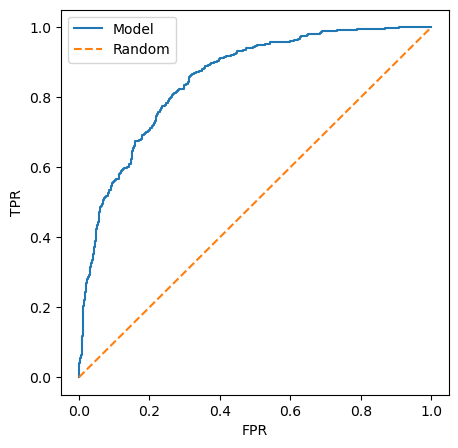

In [277]:
plt.figure(figsize=(5, 5))

plt.plot(fpr, tpr, label='Model')
plt.plot([0, 1], [0, 1], label='Random', linestyle='--')

plt.xlabel('FPR')
plt.ylabel('TPR')

plt.legend()
# النتيجة لو كان خط مستقيم يعني النموذج غبي ومش فاهم اشي لو كان رايح باتجاخه الايسري العلوية  بكون النموذج جيد لو كان رايح باتجاه القطر ٠.٥ هادا نموذج ضعيف نموذج يكون بالنص
# خط مايل مستقم نموذج فاشل 
# خط مقوس ومنحني ومايل لفوق الابسر نموذج ناجح 

In [279]:
from sklearn.metrics import roc_auc_score
# هان نستدعي الدالة الي  بتعطينا رقم تحت المنحني وجودة النموذة 

roc_auc_score(y_val, y_pred)
# قيم الواقع وتوقع وناتية ٠.٨٥ يعني النموذج جيد جدا 

0.8518124585314959

In [280]:
def train(df_train, y_train, C=1.0):# دالة تدريب تكون ماخذة قيم تدريب ونتايج والعتبة 
    dicts = df_train[categorical + numerical].to_dict(orient='records')
# هان بنحول بيانت التدريب القاموس كل صف لوحده
    dv = DictVectorizer(sparse=False)
    # هان عشان نحول القاموس للمصفوفة ونجيب منه الاعمدة الفرعية من القيم الفئوية ورقيمة اعمدة الفئات 
    X_train = dv.fit_transform(dicts)
# نعمل تدريب وتحويل الي ارقام 
    model = LogisticRegression(C=C, max_iter=1000)
    # هان بندرب النومذج علي الاوزان والعتبة و عدد البيانات 
    model.fit(X_train, y_train)
    # نجيب الاوزان المضبوطة 
    return dv, model
    # هان بنرجع الاعمدة الاحادية والنموذج الي حيدرب 

In [281]:
def predict(df, dv, model):# الحين دالة التوقع 
    dicts = df[categorical + numerical].to_dict(orient='records')
# بتحتوي علي بيانات يا ما التحقق او الاختبار تحولهم للقلموس 
    X = dv.transform(dicts)
    # هان نجيب الاعنمدة بدون تدريب بس تحويل 
    y_pred = model.predict_proba(X)[:, 1]
# هان بنتوقع وبنجيب الاوزان من المديول بنجيب التوقع قيمة الايجابية الي بتكون واح 
    return y_pred
    # نستدعي التوقع 

In [282]:
from sklearn.model_selection import KFold
# هادا بنستدعيس دالة التقسيم 
# تنبيه الدالة تستخدم بحالة البانات الصغيرة او نتاكد انو النموذج مستقر 
kfold = KFold(n_splits=5, shuffle=True, random_state=1)
# نقسم لخمس المجموعات نلخبطهم ونخلي عشواي يحافظ علي القيم يثبتهم 

In [285]:
#from tqdm.auto import tqdm

n_splits = 5
# هان بدنا نجرب العتبات 
# تقسيمة خممس مجموعات 
for C in tqdm([0.001, 0.01, 0.1, 0.5, 1, 5, 10]):# اعتبات وكل عتبة بكون الها متوسط وكمان انحراف معياري 
    kfold = KFold(n_splits=n_splits, shuffle=True, random_state=1)# نقسمهم باستدعا دالة التقسيم 

    scores = []# لستت النتايج 

    for train_idx, val_idx in kfold.split(df_full_train):# لاوب علي قسم تدريب وتحقق نجمعهم عشان نقسمهم في كفولد 
        # نحدد بيانات التدريب وتحقق 
        df_train = df_full_train.iloc[train_idx]
        df_val = df_full_train.iloc[val_idx]
# نحدد النتايج تدريب وتحقق 
        y_train = df_train.churn.values
        y_val = df_val.churn.values
# هان نجيب الاعمدة الاحتادية وتدريب نموذج مد دالة التدريب نحط فيها القيم ونتايج والعتبة المختارة كل مرة مختلفة حسب اللوب 
        dv, model = train(df_train, y_train, C=C)
        y_pred = predict(df_val, dv, model)
# بعديين نعمل توقع علي بيانات التحقق عن طريقة دالة التوقع 
        auc = roc_auc_score(y_val, y_pred)
        # بعدين نجيب القيمة الدقة النموذج في ترتيب البيانات 
        scores.append(auc)
        # نحط النتايج في ليستت النتايج 

    print('C=%s %.3f +- %.3f' % (C, np.mean(scores), np.std(scores)))

  0%|          | 0/7 [00:00<?, ?it/s]

C=0.001 0.825 +- 0.009


/opt/anaconda3/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:473: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/opt/anaconda3/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:473: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please a

C=0.01 0.840 +- 0.008


/opt/anaconda3/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:473: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/opt/anaconda3/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:473: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please a

C=0.1 0.842 +- 0.007


/opt/anaconda3/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:473: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/opt/anaconda3/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:473: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please a

C=0.5 0.842 +- 0.007


/opt/anaconda3/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:473: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/opt/anaconda3/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:473: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please a

C=1 0.842 +- 0.007


/opt/anaconda3/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:473: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/opt/anaconda3/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:473: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please a

C=5 0.842 +- 0.007


/opt/anaconda3/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:473: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/opt/anaconda3/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:473: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please a

C=10 0.842 +- 0.007
